# What drives xG at the 2022 World Cup, and how Argentina and France fit the pattern

Reproduces every number and figure in the README. Runs top to bottom from a clean clone
(the first run downloads ~230k events from StatsBomb open data and caches them in `data/`).

In [1]:
import sys; sys.path.insert(0, "../src")
import pandas as pd
import data, metrics as M, model, final, plots
pd.set_option("display.precision", 2, "display.width", 160)

## 1. Data: every match, one row per team per match (regulation time only)

In [2]:
ev = M.prepare(data.events())
matches = data.matches()
fid = data.final_match_id()
tm = M.team_match_table(ev, matches)              # periods 1-2 only; shootout and extra time excluded
base, fin = tm[tm.match_id != fid], tm[tm.match_id == fid]
print(f"{ev.match_id.nunique()} matches, {len(ev):,} events; baseline rows: {len(base)}, final rows: {len(fin)}")

64 matches, 234,637 events; baseline rows: 126, final rows: 2


**Sanity check:** regulation-time goals in the table should match the known scorelines (for example, the final was 2–2 after 90 minutes).

In [3]:
chk = tm.groupby("match_id").goals.sum().rename("goals_in_table").to_frame()
reg = ev[(ev.period <= 2) & (ev.type == "Shot") & (ev.shot_outcome == "Goal")].groupby("match_id").size()
own = ev[(ev.period <= 2) & (ev.type == "Own Goal For")].groupby("match_id").size()
chk["shot_goals"] = reg.reindex(chk.index, fill_value=0)
print("own goals (counted in score, not in xG):", int(own.sum()))
print("table goals == shot goals for every match:", (chk.goals_in_table == chk.shot_goals).all())
tm[tm.team == "Argentina"][["date", "opponent", "goals", "xg", "pen_xg", "minutes"]]

own goals (counted in score, not in xG): 3
table goals == shot goals for every match: True


,date,opponent,goals,xg,pen_xg,minutes
92,2022-11-22,Saudi Arabia,1,2.49,0.78,110.22
70,2022-11-26,Mexico,2,0.33,0.00,101.97
21,2022-11-30,Poland,2,3.08,0.78,99.10
100,2022-12-03,Australia,2,1.48,0.00,99.44
113,2022-12-09,Netherlands,2,1.44,0.78,108.74
120,2022-12-13,Croatia,3,1.86,0.78,99.24
126,2022-12-18,France,2,1.62,0.78,106.21


The 12 metrics (none use shots or xG, so the target cannot leak into the predictors):

In [4]:
pd.DataFrame(M.METRICS, index=["pillar", "definition"]).T

,pillar,definition
possession_share,Build-up,Share of all passes in the match made by the team
passes_per_possession,Build-up,Open-play passes per team possession
pass_completion_under_pressure,Build-up,Completion rate of open-play passes made under...
progressive_passes_p90,Progression,Completed open-play passes that cut the distan...
progressive_carries_p90,Progression,Carries of 5+ units that cut the distance to g...
directness,Progression,Average forward gain (x) per open-play pass
long_ball_share,Progression,Share of open-play passes of 35+ units
field_tilt,Territory,Team share of both teams' passes made in the f...
crosses_per_entry,Territory,Open-play crosses per final-third entry
pressures_per_opp_possession,Pressing,Pressures per opponent possession


## 2. Tournament baseline: PCA, then xG/90 on the components

In [5]:
b = model.fit(base)
scored = b.score(base)
score_sd = scored[model.PCS].std()
print("variance explained:", b.explained.round(3).to_dict(), " cumulative:", round(b.explained.sum(), 2))
print("R²:", round(b.ols.rsquared, 3))
effect = b.coefs.loc[model.PCS].mul(score_sd, axis=0)[["coef", "lo", "hi"]].assign(p=b.coefs.p)
effect.index = [model.NAMES[p] for p in effect.index]
effect.round(3)

variance explained: {'PC1': 0.501, 'PC2': 0.132, 'PC3': 0.086, 'PC4': 0.07, 'PC5': 0.058}  cumulative: 0.85
R²: 0.348


,coef,lo,hi,p
Control,2.86e-01,1.75e-01,0.40,0.00
Direct & wide,2.19e-01,1.07e-01,0.33,0.00
Pressing volume,1.18e-01,-2.00e-03,0.24,0.05
Pressing height,-8.00e-03,-1.17e-01,0.10,0.88
Ball-carrying,1.90e-01,8.70e-02,0.29,0.00


In [6]:
b.loadings.rename(columns=model.NAMES).round(2)

,Control,Direct & wide,Pressing volume,Pressing height,Ball-carrying
possession_share,0.37,0.05,-0.10,-0.14,-0.09
passes_per_possession,0.35,-0.17,0.04,-0.05,0.16
pass_completion_under_pressure,0.24,-0.28,0.36,-0.37,-0.46
progressive_passes_p90,0.33,0.26,0.01,0.06,0.14
progressive_carries_p90,0.25,0.22,0.29,-0.14,0.69
directness,-0.33,0.35,-0.06,0.19,0.02
long_ball_share,-0.32,0.29,0.05,0.01,-0.13
field_tilt,0.38,0.16,-0.04,0.11,-0.12
crosses_per_entry,-0.11,0.49,0.52,-0.39,-0.23
pressures_per_opp_possession,-0.10,-0.31,0.70,0.54,0.09


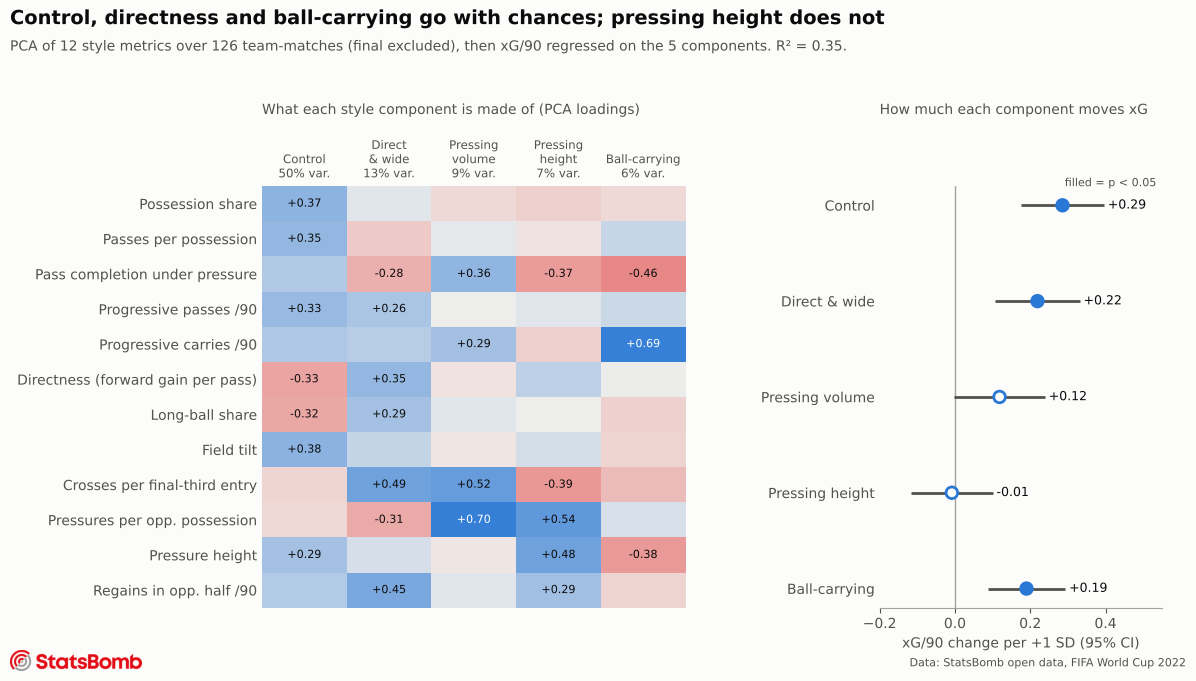

In [7]:
plots.what_drives_xg(b, score_sd);

**Penalty check:** refit on non-penalty xG. If the same components matter, penalties are not driving the model.

In [8]:
bn = model.fit(base, "npxg_p90")
print("R² (npxG):", round(bn.ols.rsquared, 3))
pd.DataFrame({"xG model": b.coefs.coef, "npxG model": bn.coefs.coef}).rename(index=model.NAMES).round(3)

R² (npxG): 0.36


,xG model,npxG model
const,1.04e+00,0.94
Control,1.16e-01,0.10
Direct & wide,1.74e-01,0.17
Pressing volume,1.16e-01,0.12
Pressing height,-9.00e-03,-0.01
Ball-carrying,2.27e-01,0.20


## 3. Team profiles: where Argentina and France sit

In [9]:
teams = scored.groupby("team").mean(numeric_only=True)
teams["pen_xg_p90"] = teams.xg_p90 - teams.npxg_p90
teams["npxg_residual"] = bn.score(base).groupby("team").residual.mean()
nscored = bn.score(base).groupby("team").mean(numeric_only=True)
teams["npxg_predicted"] = nscored.predicted
for pc in model.PCS:
    teams[f"rank_{model.NAMES[pc]}"] = teams[pc].rank(ascending=False).astype(int)
teams["rank_xg"] = teams.xg_p90.rank(ascending=False).astype(int)
teams["rank_predicted"] = teams.predicted.rank(ascending=False).astype(int)
cols = ["xg_p90", "predicted", "residual", "pen_xg_p90", "npxg_residual", "rank_xg", "rank_predicted"] + [c for c in teams if c.startswith("rank_") and c not in ("rank_xg", "rank_predicted")]
teams.loc[["Argentina", "France"], cols].T

team,Argentina,France
xg_p90,1.56,1.41
predicted,1.23,1.33
residual,0.33,0.08
pen_xg_p90,0.45,0.00
npxg_residual,0.01,0.22
rank_xg,3.00,5.00
rank_predicted,6.00,4.00
rank_Control,8.00,12.00
rank_Direct & wide,31.00,19.00
rank_Pressing volume,5.00,13.00


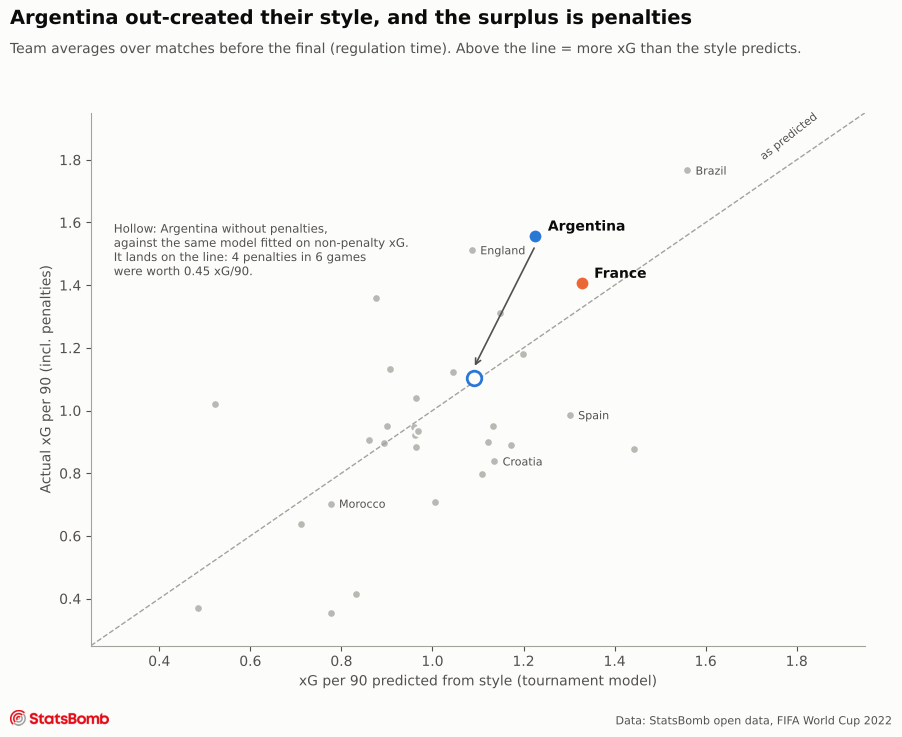

In [10]:
plots.actual_vs_predicted(teams);

In [11]:
teams.sort_values("xg_p90", ascending=False)[["xg_p90", "predicted", "residual", "pen_xg_p90"]].head(10)

,xg_p90,predicted,residual,pen_xg_p90
team,,,,
Germany,2.43,1.48,0.94,0.23
Brazil,1.77,1.56,0.21,0.14
Argentina,1.56,1.23,0.33,0.45
England,1.51,1.09,0.43,0.27
France,1.41,1.33,0.08,0.00
Switzerland,1.36,0.88,0.48,0.00
Portugal,1.31,1.15,0.16,0.27
Canada,1.18,1.20,-0.02,0.23
Ecuador,1.13,0.91,0.23,0.23


## 4. The final

In [12]:
fs = b.score(fin).set_index("team")
fs[[*model.PCS, "predicted", "xg_p90", "residual"]].rename(columns=model.NAMES)

,Control,Direct & wide,Pressing volume,Pressing height,Ball-carrying,predicted,xg_p90,residual
team,,,,,,,,
Argentina,-0.10,1.14,-0.59,-0.98,0.57,1.30,1.37,0.08
France,-0.45,-1.14,-0.05,0.54,0.17,0.82,0.98,0.16


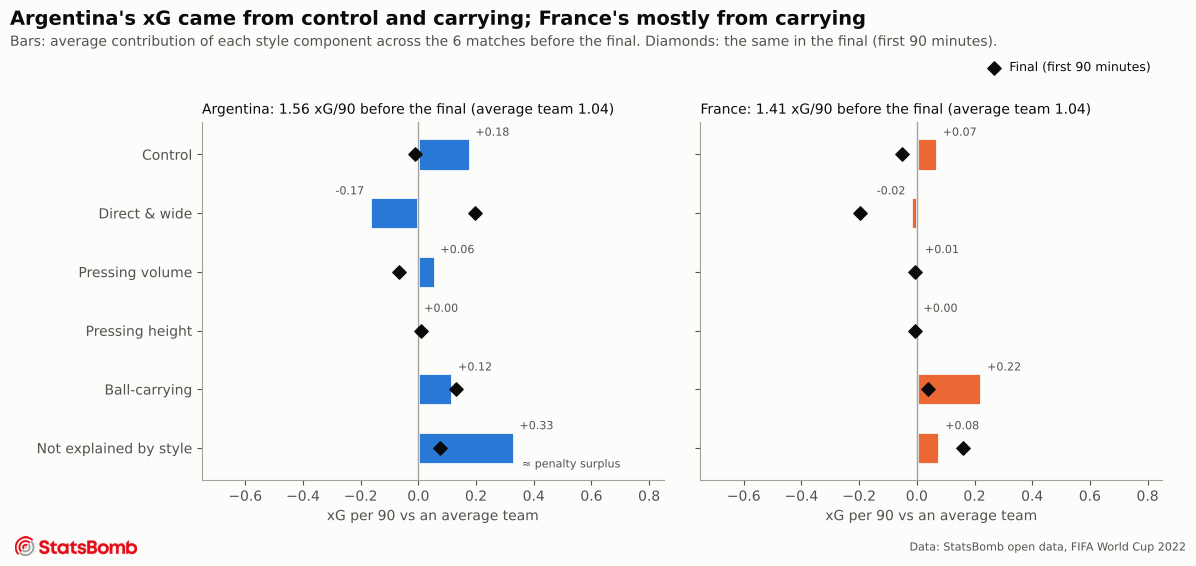

In [13]:
plots.team_contributions(teams, fs, b.ols.params["const"]);

Each metric in the final (first 90 minutes) as a z-score against the team's own 6 earlier matches:

In [14]:
z = {}
for t in ["Argentina", "France"]:
    own = base[base.team == t][list(M.METRICS)]
    z[t] = (fs.loc[t, list(M.METRICS)] - own.mean()) / own.std()
pd.DataFrame(z).astype(float).round(1)

,Argentina,France
possession_share,-0.3,-0.4
passes_per_possession,-0.5,-1.3
pass_completion_under_pressure,-2.6,0.7
progressive_passes_p90,-0.0,-1.3
progressive_carries_p90,-0.5,-0.8
directness,0.7,0.4
long_ball_share,-0.0,-0.1
field_tilt,-0.1,-0.8
crosses_per_entry,1.6,-0.9
pressures_per_opp_possession,-1.9,0.3


Ground truth for the score-state split (from the event data, not memory):

In [15]:
fe = ev[ev.match_id == fid]
display(final.goals(fe))
final.substitutions(fe)

,period,minute,second,team,player,shot_type
103561,1,22,24,Argentina,Lionel Andrés Messi Cuccittini,Penalty
103563,1,35,22,Argentina,Ángel Fabián Di María Hernández,Open Play
103570,2,79,24,France,Kylian Mbappé Lottin,Penalty
103571,2,80,59,France,Kylian Mbappé Lottin,Open Play
103583,4,107,58,Argentina,Lionel Andrés Messi Cuccittini,Open Play
103585,4,117,5,France,Kylian Mbappé Lottin,Penalty


,period,minute,second,team,player,substitution_replacement,substitution_outcome
103717,1,40,32,France,Ousmane Dembélé,Randal Kolo Muani,Tactical
103718,1,41,1,France,Olivier Giroud,Marcus Thuram,Tactical
103719,2,63,51,Argentina,Ángel Fabián Di María Hernández,Marcos Javier Acuña,Tactical
103720,2,70,27,France,Theo Bernard François Hernández,Eduardo Camavinga,Tactical
103721,2,70,29,France,Antoine Griezmann,Kingsley Coman,Tactical
103722,3,90,0,Argentina,Nahuel Molina Lucero,Gonzalo Ariel Montiel,Tactical
103723,3,95,10,France,Adrien Rabiot,Youssouf Fofana,Tactical
103724,3,101,37,Argentina,Rodrigo Javier De Paul,Leandro Daniel Paredes,Tactical
103725,3,101,49,Argentina,Julián Álvarez,Lautaro Javier Martínez,Tactical
103726,4,112,28,France,Raphaël Varane,Ibrahima Konaté,Injury


In [16]:
w = final.by_window(fe)
w[["minutes", "xg", "xg_p90", "possession_share", "pressure_height", "progressive_carries_p90", "pressures_per_opp_possession"]]

minutes    xg  xg_p90  possession_share  pressure_height  progressive_carries_p90  pressures_per_opp_possession
window               team                                                                                                                      
0–22'\n0–0           Argentina    20.90  0.19    0.84              0.59            54.57                    12.92                          1.60
                     France       20.90  0.00    0.00              0.41            52.01                     8.61                          1.44
22–79'\nARG lead     Argentina    63.40  1.35    1.92              0.51            54.98                    17.04                          1.04
                     France       63.40  0.15    0.21              0.49            57.95                    17.04                          1.76
79–90'\nFRA comeback Argentina    19.22  0.07    0.34              0.50            38.15                     9.37                          1.22
                     France       19.22  1.01    4.74              0.50            64.56                    28.10                          1.56
91–120'\nextra time  Argentina    35.20  1.14    2.91              0.63            50.76                    15.34                          1.64
                     France       35.20  1.11    2.85              0.37            50.71                     7.67                          1.81

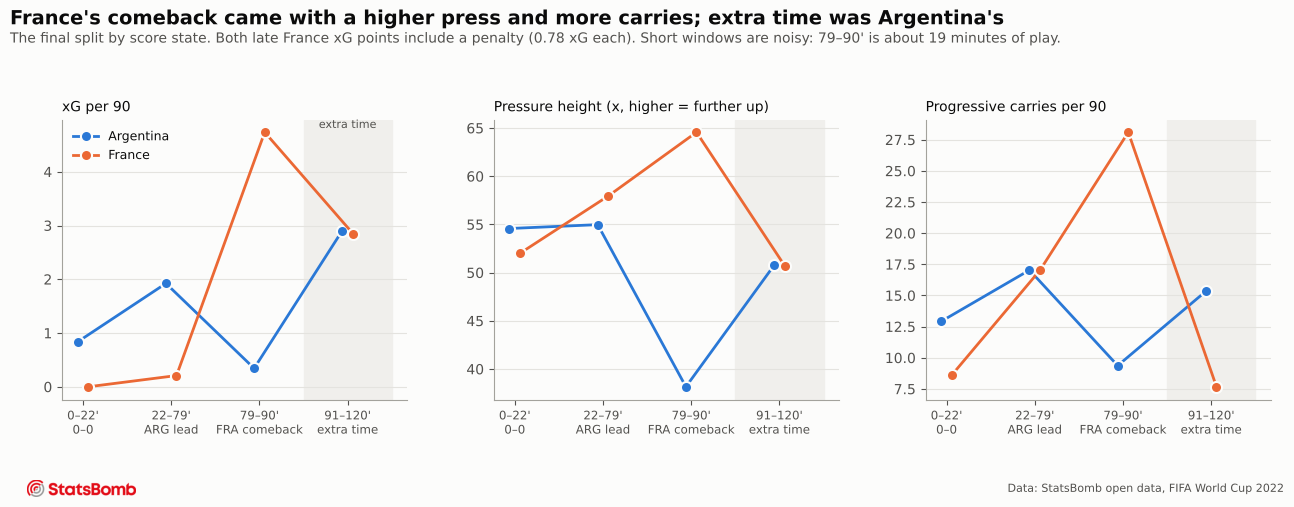

In [17]:
plots.final_by_game_state(w);

**A pointer for future work:** where Argentina entered the final third in the final, before and after Di María went off (63:51).

In [18]:
a = ev[(ev.team == "Argentina") & (ev.period <= 2)]
ent = a[a.type.isin(["Pass", "Carry"]) & (a.x < 80) & (a.end_x >= 80) & ((a.type == "Carry") | a.completed)]
ent = ent.assign(side=pd.cut(ent.end_y, [-1, 80 / 3, 160 / 3, 81], labels=["left", "centre", "right"]))
f = ent[ent.match_id == fid]
f = f.assign(phase=((f.period == 1) | (f.minute < 64)).map({True: "0–63' (Di María on)", False: "64–90'"}))
print("Earlier matches, share by side:", ent[ent.match_id != fid].side.value_counts(normalize=True).round(2).to_dict())
display(pd.crosstab(f.phase, f.side, margins=True))
a[(a.match_id == fid) & a.pass_cross].groupby("player").size().rename("crosses in the final (90 min)")

Earlier matches, share by side: {'right': 0.47, 'left': 0.33, 'centre': 0.2}


side,left,centre,right,All
phase,,,,
0–63' (Di María on),11,5,9,25
64–90',4,1,3,8
All,15,6,12,33


player
Julián Álvarez                     1
Nicolás Alejandro Tagliafico       1
Rodrigo Javier De Paul             4
Ángel Fabián Di María Hernández    6
Name: crosses in the final (90 min), dtype: int64